# MPPI on Bench-MR polygon tasks

This notebook runs the current circular differential-drive MPPI controller on imported Bench-MR polygon scenes. Static obstacles are evaluated by MPPI; ORCA has no role in these single-robot runs.

In [10]:
from argparse import Namespace
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image as NotebookImage, Markdown, display
from PIL import Image, ImageDraw, ImageFont

ROOT = Path.cwd().resolve()
if ROOT.name == 'benchmarks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
from bench_mr import evaluate, plot_results, save_results, write_report

SUITE_PATH = ROOT / 'benchmarks/bench_mr_tasks.json'
suite = json.loads(SUITE_PATH.read_text())
print(f"Loaded {len(suite['tasks'])} tasks from Bench-MR revision {suite['revision'][:8]}")

Loaded 25 tasks from Bench-MR revision c10ef1c8


## Configuration

The five `testing_...` tasks have coordinates consistent with the bundled maps. Set `TASK_IDS = None` to evaluate all 25 imported tasks. To use manual coordinates, set `CUSTOM_WORLD` and enter `[x, y, theta]` for `CUSTOM_START` and `CUSTOM_GOAL`; this overrides `TASK_IDS`.

In [11]:
TASK_IDS = [
    #'testing_parking1',
    #'testing_parking2',
    #'testing_parking3',
    #'testing_warehouse',
    'testing_warehouse2',
]

# Optional manual task. Available worlds: parking1, parking2, parking3, warehouse, warehouse2.
CUSTOM_WORLD = 'warehouse2'             # Example: 'warehouse2'
CUSTOM_START = [10.0, -70.5, 0.0]  # [x, y, theta in radians]
CUSTOM_GOAL = [110.0, -70.5, 0.0]  # [x, y, theta in radians]

REPEATS = 1
SEED = 42
MAX_STEPS = 2000
TIMEOUT_SECONDS = 60.0
ROBOT_RADIUS = 0.3
ROBOT_MAX_SPEED = 50.0       # Original example: 1.0 units/s
ROBOT_MIN_SPEED = -0.01
ROBOT_MAX_ANGULAR_SPEED = 10.0
GOAL_TOLERANCE = 0.3
HEADING_TOLERANCE = 0.15
OUTPUT = ROOT / 'benchmarks/results/notebook'

args = Namespace(
    repeats=REPEATS, seed=SEED, max_steps=MAX_STEPS, timeout=TIMEOUT_SECONDS,
    radius=ROBOT_RADIUS, max_speed=ROBOT_MAX_SPEED, min_speed=ROBOT_MIN_SPEED,
    max_angular_speed=ROBOT_MAX_ANGULAR_SPEED, goal_tolerance=GOAL_TOLERANCE,
    heading_tolerance=HEADING_TOLERANCE, output=OUTPUT,
)
if CUSTOM_WORLD is None:
    selected_tasks = [task for task in suite['tasks'] if TASK_IDS is None or task['id'] in TASK_IDS]
    unknown = set(TASK_IDS or []) - {task['id'] for task in selected_tasks}
    if unknown:
        raise ValueError(f'Unknown task IDs: {sorted(unknown)}')
else:
    if CUSTOM_WORLD not in suite['worlds']:
        raise ValueError(f"Unknown world {CUSTOM_WORLD!r}; choose from {sorted(suite['worlds'])}")
    start = np.asarray(CUSTOM_START, dtype=float)
    goal = np.asarray(CUSTOM_GOAL, dtype=float)
    if start.shape != (3,) or goal.shape != (3,) or not np.isfinite([start, goal]).all():
        raise ValueError('CUSTOM_START and CUSTOM_GOAL must contain finite [x, y, theta] values')
    selected_tasks = [{
        'id': f'custom_{CUSTOM_WORLD}', 'world': CUSTOM_WORLD, 'group': 'custom',
        'start': start.tolist(), 'goal': goal.tolist(), 'original_robot': 'custom',
    }]
if not selected_tasks:
    raise ValueError("No tasks selected. Add a TASK_IDS entry or set CUSTOM_WORLD.")
print(f'Selected {len(selected_tasks)} tasks; results will be saved to {OUTPUT}')

Selected 1 tasks; results will be saved to /home/drozdov_dan/projects/MPPI-Collision-Avoidance/benchmarks/results/notebook


## Run

The native sampler is seeded for each repeat. Results are saved after every run, so completed trajectories remain available if execution is interrupted.

In [ ]:
results = []
started = time.perf_counter()
for task in selected_tasks:
    for repeat in range(REPEATS):
        result = evaluate(task, suite['worlds'][task['world']], args, SEED + repeat)
        results.append(result)
        save_results(suite, results, args)
        print(
            f"{result['task']} seed={result['seed']}: {result['status']}, "
            f"goal distance={result['goal_distance']:.3f}, steps={result['steps']}"
        )
plot_results(suite, results, OUTPUT)
write_report(suite, results, args)
print(f'Finished in {time.perf_counter() - started:.1f} s')

## Metrics

In [ ]:
metric_columns = [
    'task', 'seed', 'status', 'steps', 'goal_distance', 'heading_error',
    'path_length', 'min_clearance', 'planning_seconds', 'mean_step_ms',
]
header = '| ' + ' | '.join(metric_columns) + ' |'
separator = '| ' + ' | '.join(['---'] * len(metric_columns)) + ' |'
rows = []
for run in results:
    values = []
    for key in metric_columns:
        value = run[key]
        values.append(f'{value:.3f}' if isinstance(value, float) else str(value))
    rows.append('| ' + ' | '.join(values) + ' |')
display(Markdown('\n'.join([header, separator, *rows])))
attempted = [run for run in results if run['status'] != 'invalid_start_or_goal']
print(f"Reached XY goal: {sum(run['success'] for run in attempted)}/{len(attempted)} attempted runs")
print(f"Collisions: {sum(run['status'] == 'collision' for run in attempted)}")

| task | seed | status | steps | goal_distance | heading_error | path_length | min_clearance | planning_seconds | mean_step_ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| custom_warehouse2 | 42 | time_limit | 250 | 63.655 | 3.083 | 90.330 | 0.056 | 59.958 | 239.832 |

Reached XY goal: 0/1 attempted runs
Collisions: 0


## Trajectories

Blue circles are starts, black stars are goals, and gray polygons are obstacles. Successful trajectories are green; unsuccessful attempted trajectories are red. The translucent circles show the robot footprint at the initial and final positions.

In [ ]:
columns = min(3, len(selected_tasks))
rows = int(np.ceil(len(selected_tasks) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(6 * columns, 5 * rows), squeeze=False, constrained_layout=True)
for ax, task in zip(axes.flat, selected_tasks):
    world = suite['worlds'][task['world']]
    for polygon in world['obstacles']:
        ax.add_patch(PolygonPatch(polygon, facecolor='0.75', edgecolor='0.35', linewidth=0.6))
    task_runs = [run for run in results if run['task'] == task['id']]
    for run in task_runs:
        states = np.asarray(run['states'])
        color = '#17855c' if run['success'] else '#c64040'
        ax.plot(states[:, 0], states[:, 1], color=color, linewidth=2, label=f"seed {run['seed']}: {run['status']}")
        ax.add_patch(Circle(states[0, :2], ROBOT_RADIUS, facecolor='#176ac6', alpha=0.25, edgecolor='none'))
        ax.add_patch(Circle(states[-1, :2], ROBOT_RADIUS, facecolor=color, alpha=0.25, edgecolor='none'))
    ax.plot(*task['start'][:2], 'o', color='#176ac6', markersize=5)
    ax.plot(*task['goal'][:2], '*', color='#111111', markersize=11)
    ax.set_title(task['id'])
    ax.set_aspect('equal')
    ax.autoscale_view()
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc='best')
for ax in list(axes.flat)[len(selected_tasks):]:
    ax.set_visible(False)
plt.show()

/tmp/ipykernel_32706/433262158.py:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Animated run

Choose one task and seed from the completed runs. The GIF is saved beside the other notebook results and displayed inline.

Saved 192 frames to /home/drozdov_dan/projects/MPPI-Collision-Avoidance/benchmarks/results/notebook/custom_warehouse2_seed_42.gif (time_limit)


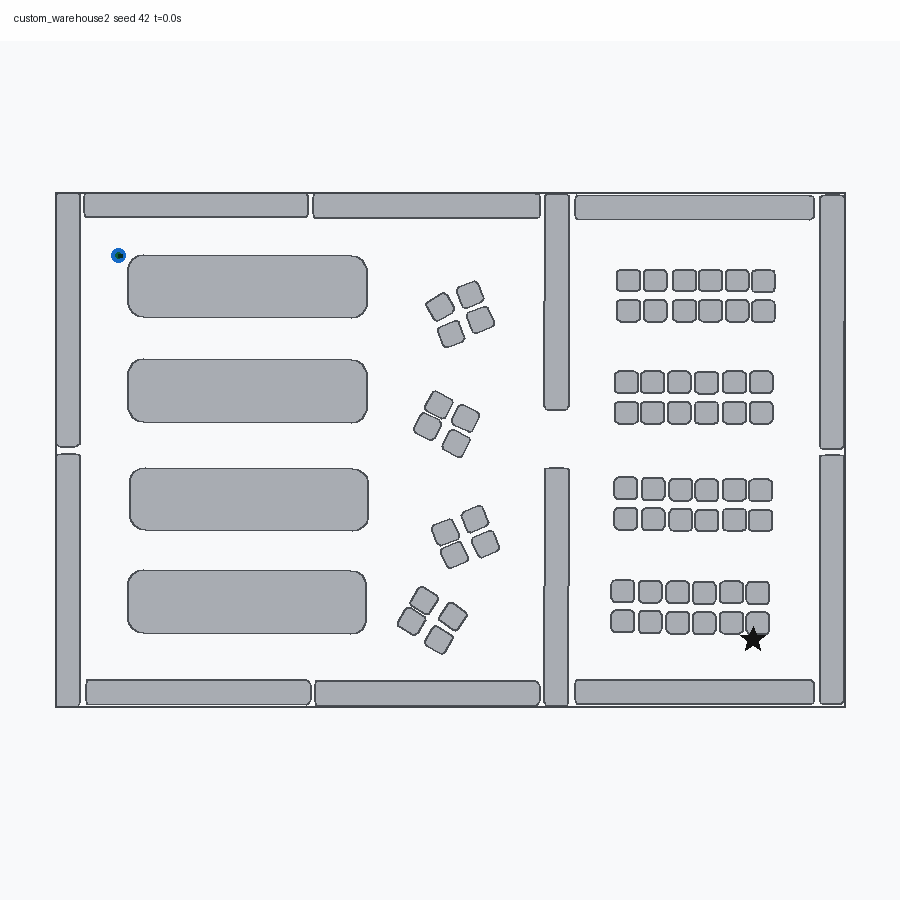

In [ ]:
ANIMATION_TASK = selected_tasks[0]['id']
ANIMATION_SEED = SEED
GIF_FRAME_DURATION_MS = 80
GIF_MAX_FRAMES = 180

animation_run = next((run for run in results if run['task'] == ANIMATION_TASK and run['seed'] == ANIMATION_SEED), None)
if animation_run is None:
    available = [(run['task'], run['seed']) for run in results]
    raise ValueError(f'Animation run not found. Available task/seed pairs: {available}')
animation_task = next(task for task in selected_tasks if task['id'] == ANIMATION_TASK)
animation_world = suite['worlds'][animation_task['world']]
animation_states = np.asarray(animation_run['states'])

canvas_size = 900
padding = 55
bounds = np.asarray(animation_world['bounds'], dtype=float)
extent = np.maximum(bounds[2:] - bounds[:2], 1e-9)
scale = (canvas_size - 2 * padding) / max(extent)
draw_width = extent[0] * scale
draw_height = extent[1] * scale
origin_x = (canvas_size - draw_width) / 2
origin_y = (canvas_size - draw_height) / 2

def to_pixel(point):
    x = origin_x + (point[0] - bounds[0]) * scale
    y = canvas_size - origin_y - (point[1] - bounds[1]) * scale
    return float(x), float(y)

def star(center, outer_radius=13, inner_radius=6):
    cx, cy = center
    points = []
    for index in range(10):
        angle = -np.pi / 2 + index * np.pi / 5
        radius = outer_radius if index % 2 == 0 else inner_radius
        points.append((cx + radius * np.cos(angle), cy + radius * np.sin(angle)))
    return points

base = Image.new('RGB', (canvas_size, canvas_size), (248, 249, 250))
base_draw = ImageDraw.Draw(base, 'RGBA')
for polygon in animation_world['obstacles']:
    base_draw.polygon([to_pixel(vertex) for vertex in polygon], fill=(168, 172, 178, 255), outline=(75, 79, 84, 255), width=2)
start_pixel = to_pixel(animation_task['start'][:2])
goal_pixel = to_pixel(animation_task['goal'][:2])
base_draw.ellipse((start_pixel[0]-7, start_pixel[1]-7, start_pixel[0]+7, start_pixel[1]+7), fill=(23, 106, 198, 255))
base_draw.polygon(star(goal_pixel), fill=(20, 20, 20, 255))
base_draw.rectangle((origin_x, origin_y, origin_x+draw_width, origin_y+draw_height), outline=(65, 69, 74, 255), width=2)

frame_indices = np.unique(np.linspace(0, len(animation_states)-1, min(len(animation_states), GIF_MAX_FRAMES), dtype=int))
frames = []
robot_radius_px = max(3, ROBOT_RADIUS * scale)
for state_index in frame_indices:
    frame = base.copy()
    draw = ImageDraw.Draw(frame, 'RGBA')
    trail = [to_pixel(state[:2]) for state in animation_states[:state_index+1]]
    if len(trail) > 1:
        draw.line(trail, fill=(23, 133, 92, 255), width=5, joint='curve')
    center = to_pixel(animation_states[state_index, :2])
    draw.ellipse((center[0]-robot_radius_px, center[1]-robot_radius_px, center[0]+robot_radius_px, center[1]+robot_radius_px), fill=(31, 157, 111, 190), outline=(12, 92, 63, 255), width=3)
    theta = animation_states[state_index, 2]
    heading_end = (center[0] + 1.5*robot_radius_px*np.cos(theta), center[1] - 1.5*robot_radius_px*np.sin(theta))
    draw.line((center, heading_end), fill=(10, 45, 32, 255), width=4)
    draw.rectangle((0, 0, canvas_size, 40), fill=(255, 255, 255, 225))
    draw.text((14, 12), f"{ANIMATION_TASK}  seed {ANIMATION_SEED}  t={state_index*0.1:.1f}s", fill=(20, 24, 28, 255))
    frames.append(frame)
for _ in range(12):
    frames.append(frames[-1].copy())
gif_path = OUTPUT / f'{ANIMATION_TASK}_seed_{ANIMATION_SEED}.gif'
gif_path.parent.mkdir(parents=True, exist_ok=True)
frames[0].save(gif_path, save_all=True, append_images=frames[1:], optimize=False, duration=GIF_FRAME_DURATION_MS, loop=0)
print(f"Saved {len(frames)} frames to {gif_path} ({animation_run['status']})")
display(NotebookImage(filename=str(gif_path), width=700))

The saved files, including the GIF, are available in `benchmarks/results/notebook/`. Position success does not imply the requested final heading was reached; inspect `heading_error` for that distinction. Warehouse timeouts mean only that the wall-time limit was reached.